In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [8]:
df = pd.read_csv("../Salary_Data.csv")
print(df.head())
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())


   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0
(30, 2)
Index(['YearsExperience', 'Salary'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes
None
       YearsExperience         Salary
count        30.000000      30.000000
mean          5.313333   76003.000000
std           2.837888   27414.429785
min           1.100000   37731.000000
25%           3.200000   56720.750000
50%           4.700000   65237.000000
75%           7.700000  100544.750000
max          10.500000  122391.000000
YearsExperience    0
Salary             0
dtype: int64
0


In [9]:
x = df[["YearsExperience"]]
y = df["Salary"]

In [10]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

In [11]:
# MODEL 1: LINEAR REGRESSION
linear_model = LinearRegression()

linear_model.fit(x_train, y_train)

linear_pred = linear_model.predict(x_test)

In [12]:

#POLYNOMIAL REGRESSION
poly = PolynomialFeatures(degree=2) 

x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)

poly_model = LinearRegression()

poly_model.fit(x_train_poly, y_train)

poly_pred = poly_model.predict(x_test_poly)

In [13]:
#RIDGE REGRESSION

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(x_train_scaled, y_train)

ridge_pred = ridge_model.predict(x_test_scaled)

In [14]:
#LASSO REGRESSION

lasso_model = Lasso(alpha=1.0)

lasso_model.fit(x_train_scaled, y_train)

lasso_pred = lasso_model.predict(x_test_scaled)

In [15]:
# EVALUATION METRICS

def evaluate_model(name, y_test, y_pred):

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)
    print("MAE      :", mae)
    print("MSE      :", mse)
    print("RMSE     :", rmse)
    print("R2 Score :", r2)

In [16]:
# Evaluation of Models

evaluate_model(
    "Linear Regression",
    y_test,
    linear_pred
)

evaluate_model(
    "Polynomial Regression",
    y_test,
    poly_pred
)

evaluate_model(
    "Ridge Regression",
    y_test,
    ridge_prede
)

evaluate_model(
    "Lasso Regression",
    y_test,
    lasso_pred
)

MAE      : 6286.453830757749
MSE      : 49830096.85590839
RMSE     : 7059.04362190151
R2 Score : 0.9024461774180497
MAE      : 6381.371429702192
MSE      : 52527916.36877501
RMSE     : 7247.614529538323
R2 Score : 0.897164578089087


NameError: name 'ridge_prede' is not defined

In [13]:
#Comparison 
results = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Polynomial Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],

    "MAE": [
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, poly_pred),
        mean_absolute_error(y_test, ridge_pred),
        mean_absolute_error(y_test, lasso_pred)
    ],

    "MSE": [
        mean_squared_error(y_test, linear_pred),
        mean_squared_error(y_test, poly_pred),
        mean_squared_error(y_test, ridge_pred),
        mean_squared_error(y_test, lasso_pred)
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_pred)),
        np.sqrt(mean_squared_error(y_test, poly_pred)),
        np.sqrt(mean_squared_error(y_test, ridge_pred)),
        np.sqrt(mean_squared_error(y_test, lasso_pred))
    ],

    "R2 Score": [
        r2_score(y_test, linear_pred),
        r2_score(y_test, poly_pred),
        r2_score(y_test, ridge_pred),
        r2_score(y_test, lasso_pred)
    ]
})

print("\nMODEL COMPARISON")
print(results)



MODEL COMPARISON
                   Model          MAE           MSE         RMSE  R2 Score
0      Linear Regression  6286.453831  4.983010e+07  7059.043622  0.902446
1  Polynomial Regression  6381.371430  5.252792e+07  7247.614530  0.897165
2       Ridge Regression  6192.215678  5.171076e+07  7191.019734  0.898764
3       Lasso Regression  6286.367060  4.983107e+07  7059.112571  0.902444


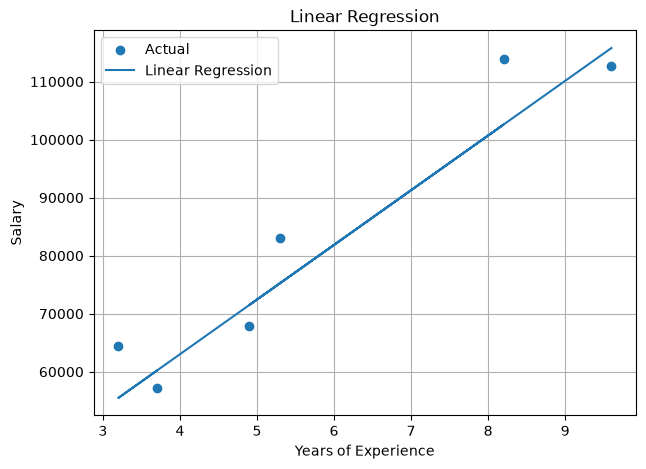

In [14]:
#Linear Regression Plot

plt.figure(figsize=(7,5))

plt.scatter(x_test, y_test, label="Actual")

plt.plot(
    x_test,
    linear_pred,
    label="Linear Regression"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression")
plt.legend()
plt.grid(True)

plt.show()


C:\Users\Adithya\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


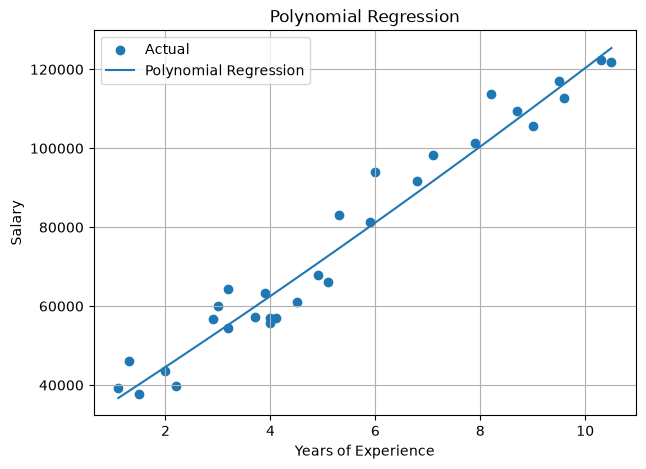

In [15]:
#Polynomial Regression Plot

x_curve = np.linspace(
    x.min(),
    x.max(),
    100
).reshape(-1, 1)

x_curve_poly = poly.transform(x_curve)

y_curve = poly_model.predict(x_curve_poly)

plt.figure(figsize=(7,5))

plt.scatter(x, y, label="Actual")

plt.plot(
    x_curve,
    y_curve,
    label="Polynomial Regression"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Polynomial Regression")
plt.legend()
plt.grid(True)

plt.show()


In [1]:
# Ridge and Lasso Comparison

plt.figure(figsize=(7,5))

plt.scatter(x_test, y_test, label="Actual")

plt.scatter(
    x_test,
    ridge_pred,
    label="Ridge Prediction"
)

plt.scatter(
    x_test,
    lasso_pred,
    label="Lasso Prediction"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Ridge vs Lasso Regression")
plt.legend()
plt.grid(True)
plt.show()

NameError: name 'plt' is not defined